# Are these two tables the same? Five whole-table fingerprints against what happens in transit

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phoebefu6/phoebe-the-builder/blob/main/data-quality-governance/table-checksum/demo.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/phoebefu6/phoebe-the-builder/main?labpath=data-quality-governance/table-checksum/demo.ipynb)

The table was copied to another system and you cannot ship both copies to one place to diff them. You can ship one
number from each side. This notebook builds a fictional 1,000-row keyless order-event export (20 exact duplicate
pairs, as event logs have), then asks five fingerprints two questions: after a benign transform (same data), do they
MATCH; after a real mutation (different data), do they DIFFER. It is not a row differ (see `data-diff`, Day 100)
or a reconciliation report (`reconciliation-checker`, Day 99); it scores the one number you compare.

1. The engine
2. Same data: which fingerprints raise a false alarm
3. Different data: which fingerprints miss it
4. The score
5. The ceiling: a half cent
6. The chart
7. Try your own

## 1. The engine

Extracted from `explore.py` and `evidence.py` at build time. Seeded (`Random(207)`), every row fictional, and every
number below matches `evidence.txt` exactly. The five fingerprints: `csv_md5` (md5 of the dump), `count_sums` (row
count + money column sums, the reconciliation habit), `xor_rows` and `sum_rows` (XOR or sum mod 2^64 of a 64-bit
hash of each row joined with `|`), and `canonical` (the sum, over a typed row: columns by name, money quantised to the
cent, NULL a distinct token, strings length-prefixed, -0 folded to 0). The study takes several seconds.

In [1]:
from __future__ import annotations

import csv
import hashlib
import io
import random
from collections import Counter
from decimal import ROUND_HALF_EVEN, Decimal
from typing import Callable, Dict, List, Optional, Tuple

import matplotlib.pyplot as plt


class _E:  # evidence.py refers to the engine as E
    pass

SEED = 207


N_ROWS = 1000


N_DUP_PAIRS = 20


TRIALS = 100


TAX = 1.07


COLS = ["event_id", "customer", "note", "amount", "discount"]


SCHEMA = {"event_id": "int", "customer": "str", "note": "str", "amount": "money", "discount": "money"}


NULL = "\\N"  # how the CSV round trip writes a NULL (Postgres COPY style)


CUSTOMERS = ["Ada Lim", "Ben Okafor", "Chloe Tan", "Dev Rao", "Eli Novak", "Fay Wong", "Gus Berg", "Hana Sato"]


NOTES = ["gift", "rush", "fragile", "repeat", "VIP"]


Row = Dict[str, object]


Table = Tuple[List[str], List[Row]]  # (column order, rows)


def amount_of(lines: List[Tuple[int, int]], reverse: bool = False) -> float:
    """Sum of price_cents/100 * qty * TAX in float, the way an order service adds it up. Order of addition matters."""
    seq = list(reversed(lines)) if reverse else lines
    total = 0.0
    for cents, qty in seq:
        total += cents / 100 * qty * TAX
    return total


def make_table(seed: int = SEED) -> Tuple[Table, Dict[int, List[Tuple[int, int]]]]:
    rng = random.Random(seed)
    rows: List[Row] = []
    items: Dict[int, List[Tuple[int, int]]] = {}
    for i in range(N_ROWS - N_DUP_PAIRS):
        lines = [(rng.randint(99, 9999), rng.randint(1, 5)) for _ in range(rng.randint(1, 6))]
        u = rng.random()
        note: Optional[str] = None if u < 0.5 else ("" if u < 0.65 else rng.choice(NOTES))
        disc: Optional[float] = None if rng.random() < 0.6 else float(rng.choice([0, 0, 5, 10, 12.5]))
        eid = 10_000 + i
        items[eid] = lines
        rows.append({"event_id": eid, "customer": rng.choice(CUSTOMERS), "note": note,
                     "amount": amount_of(lines), "discount": disc})
    for r in rng.sample(rows, N_DUP_PAIRS):  # a keyless event log: a retry wrote some events twice
        rows.append(dict(r))
    rng.shuffle(rows)
    return (list(COLS), rows), items


def h64(s: str) -> int:
    return int.from_bytes(hashlib.md5(s.encode()).digest()[:8], "big")


def csv_md5(t: Table) -> str:
    cols, rows = t
    buf = io.StringIO()
    w = csv.writer(buf, lineterminator="\n")
    w.writerow(cols)
    for r in rows:
        w.writerow(["" if r[c] is None else r[c] for c in cols])
    return hashlib.md5(buf.getvalue().encode()).hexdigest()


def money(v: object) -> Decimal:
    d = Decimal(repr(v)) if isinstance(v, float) else Decimal(str(v))
    d = d.quantize(Decimal("0.01"), rounding=ROUND_HALF_EVEN)
    return Decimal("0.00") if d == 0 else d  # -0.00 and 0.00 are the same amount


def sum_col(rows: List[Row], c: str) -> Decimal:
    return sum((money(r[c]) for r in rows if r[c] not in (None, NULL)), Decimal("0.00"))


def count_sums(t: Table) -> str:
    cols, rows = t
    return "|".join([str(len(rows))] + [str(sum_col(rows, c)) for c in sorted(cols) if SCHEMA.get(c) == "money"])


def naive_row(cols: List[str], r: Row) -> str:
    return "|".join(str(r[c]) for c in cols)


def xor_rows(t: Table) -> str:
    acc = 0
    for r in t[1]:
        acc ^= h64(naive_row(t[0], r))
    return f"{acc:016x}"


def sum_rows(t: Table) -> str:
    acc = sum(h64(naive_row(t[0], r)) for r in t[1]) % 2**64
    return f"{acc:016x}"


def canon_value(kind: str, v: object) -> str:
    if v is None or v == NULL:
        return "\x00N"
    if kind == "int":
        return f"i{int(v)}"
    if kind == "money":
        return f"m{money(v)}"
    s = str(v)
    return f"s{len(s)}:{s}"


def canonical_row(r: Row) -> str:
    return "".join(canon_value(SCHEMA[c], r[c]) for c in sorted(SCHEMA))


def canonical(t: Table) -> str:
    acc = sum(h64(canonical_row(r)) for r in t[1]) % 2**64
    return f"{acc:016x}"


SCHEMES: Dict[str, Callable[[Table], str]] = {
    "csv_md5": csv_md5, "count_sums": count_sums, "xor_rows": xor_rows, "sum_rows": sum_rows, "canonical": canonical,
}


def _copy(t: Table) -> Table:
    return list(t[0]), [dict(r) for r in t[1]]


def b_shuffle(t, items, rng):
    c = _copy(t)
    rng.shuffle(c[1])
    return c


def b_reorder_columns(t, items, rng):
    cols = list(t[0])
    while cols == t[0]:
        rng.shuffle(cols)
    return cols, [dict(r) for r in t[1]]


def b_csv_roundtrip(t, items, rng):
    """Every value comes back a string, NULL as \\N, floats as Python writes them."""
    return list(t[0]), [{c: NULL if v is None else str(v) for c, v in r.items()} for r in t[1]]


def b_export_15g(t, items, rng):
    """The target exports floats with 15 significant digits, as many databases and spreadsheets do."""
    return list(t[0]), [{c: (float(f"{v:.15g}") if isinstance(v, float) else v) for c, v in r.items()} for r in t[1]]


def b_recompute_amount(t, items, rng):
    """The target re-adds the same line items in the opposite order."""
    c = _copy(t)
    for r in c[1]:
        r["amount"] = amount_of(items[r["event_id"]], reverse=True)
    return c


def b_negative_zero(t, items, rng):
    c = _copy(t)
    for r in c[1]:
        if r["discount"] == 0:
            r["discount"] = -0.0
    return c


def b_int_discount(t, items, rng):
    """The target stores whole-number discounts in an integer column: 5.0 comes back as 5."""
    c = _copy(t)
    for r in c[1]:
        if isinstance(r["discount"], float) and r["discount"].is_integer():
            r["discount"] = int(r["discount"])
    return c


def m_one_cent(t, items, rng):
    c = _copy(t)
    r = rng.choice(c[1])
    r["amount"] = r["amount"] + 0.01
    return c


def m_offsetting_cents(t, items, rng):
    c = _copy(t)
    a, b = rng.sample(c[1], 2)
    a["amount"], b["amount"] = a["amount"] + 0.01, b["amount"] - 0.01
    return c


def m_swap_amounts(t, items, rng):
    c = _copy(t)
    a, b = rng.sample([r for r in c[1]], 2)
    a["amount"], b["amount"] = b["amount"], a["amount"]
    return c


def m_null_to_empty(t, items, rng):
    c = _copy(t)
    rng.choice([r for r in c[1] if r["note"] is None])["note"] = ""
    return c


def m_dup_pair_swapped(t, items, rng):
    """The dedup step dropped both copies of a retried event, and a retry wrote another event twice more."""
    c = _copy(t)
    keys = Counter(naive_row(COLS, r) for r in c[1])
    dup = rng.choice([r for r in c[1] if keys[naive_row(COLS, r)] == 2])
    gone = naive_row(COLS, dup)
    rows = [r for r in c[1] if naive_row(COLS, r) != gone]
    extra = rng.choice([r for r in rows if keys[naive_row(COLS, r)] == 1])
    return list(c[0]), rows + [dict(extra), dict(extra)]


BENIGN = {"shuffle rows": b_shuffle, "reorder columns": b_reorder_columns, "CSV round trip": b_csv_roundtrip,
          "export at 15 digits": b_export_15g, "re-add line items": b_recompute_amount,
          "-0.0 discount": b_negative_zero, "5.0 stored as 5": b_int_discount}


MUTATIONS = {"one amount +1 cent": m_one_cent, "two offsetting cents": m_offsetting_cents,
             "two amounts swapped": m_swap_amounts, "NULL note became ''": m_null_to_empty,
             "dup pair dropped, another doubled": m_dup_pair_swapped}


def delimiter_case(t: Table, rng: random.Random) -> Tuple[Table, Table]:
    """Two tables identical except one row's customer/note boundary: 'Ada Lim|' + 'VIP' vs 'Ada Lim' + '|VIP'."""
    a, b = _copy(t), _copy(t)
    i = rng.choice([j for j, r in enumerate(t[1]) if r["note"]])
    a[1][i]["customer"] = t[1][i]["customer"] + "|"
    b[1][i]["note"] = "|" + t[1][i]["note"]
    return a, b


def score(t: Table, items: Dict[int, List[Tuple[int, int]]], trials: int = TRIALS) -> dict:
    """Per transform, per scheme: share of seeded trials where the fingerprints MATCH."""
    base = {k: f(t) for k, f in SCHEMES.items()}
    out: dict = {"benign": {}, "mutations": {}}
    for group, table in (("benign", BENIGN), ("mutations", MUTATIONS)):
        for name, fn in table.items():
            rng = random.Random(f"{SEED}-{name}")
            n = 1 if name in ("CSV round trip", "export at 15 digits", "re-add line items", "-0.0 discount",
                              "5.0 stored as 5") else trials
            match = {k: 0 for k in SCHEMES}
            for _ in range(n):
                u = fn(t, items, rng)
                for k, f in SCHEMES.items():
                    match[k] += f(u) == base[k]
            out[group][name] = {"trials": n, "match": {k: v / n for k, v in match.items()}}
    rng = random.Random(f"{SEED}-delim")
    match = {k: 0 for k in SCHEMES}
    for _ in range(trials):
        a, b = delimiter_case(t, rng)
        for k, f in SCHEMES.items():
            match[k] += f(a) == f(b)
    out["mutations"]["'|' moved across a column"] = {"trials": trials, "match": {k: v / trials for k, v in match.items()}}
    return out


def float_detail(t: Table, items: Dict[int, List[Tuple[int, int]]]) -> dict:
    """Where the re-added amounts disagree: in the bits, and after rounding to the cent."""
    bits = cents = export15 = 0
    straddle: List[Tuple[int, str, str]] = []
    for r in t[1]:
        a, b = r["amount"], amount_of(items[r["event_id"]], reverse=True)
        bits += a != b
        if money(a) != money(b):
            cents += 1
            straddle.append((r["event_id"], repr(a), repr(b)))
        export15 += money(a) != money(float(f"{a:.15g}"))
    exact = sum(1 for r in t[1] if (sum(c * q for c, q in items[r["event_id"]]) * 107) % 100 == 50)
    return {"rows": len(t[1]), "bits_differ": bits, "cents_differ": cents, "export15_cents_differ": export15,
            "half_cent_exact": exact, "straddle": straddle[:5]}


def study() -> dict:
    t, items = make_table()
    keys = [naive_row(COLS, r) for r in t[1]]
    return {"rows": len(t[1]), "distinct": len(set(keys)), "dup_pairs": N_DUP_PAIRS, "trials": TRIALS,
            "nulls": sum(r["note"] is None for r in t[1]), "empties": sum(r["note"] == "" for r in t[1]),
            "scores": score(t, items), "float": float_detail(t, items)}


E = _E()
E.__dict__.update(globals())

def tally(r: dict) -> dict:
    """Per scheme: benign transforms it false-alarms on (matched in <100% of trials) and mutations it misses (>0%)."""
    out = {}
    for k in E.SCHEMES:
        fa = [n for n, v in r["scores"]["benign"].items() if v["match"][k] < 1]
        miss = [n for n, v in r["scores"]["mutations"].items() if v["match"][k] > 0]
        out[k] = {"false_alarms": fa, "misses": miss}
    return out


def lines(r: dict) -> List[str]:
    out: List[str] = []
    w = out.append
    s, f = r["scores"], r["float"]
    w(
        f"table-checksum evidence  (fictional keyless order-event export, {r['rows']:,} rows, {r['distinct']} distinct, "
        f"{r['dup_pairs']} exact duplicate pairs; note column {r['nulls']} NULL and {r['empties']} empty string; "
        f"amount = float sum of line items x {E.TAX}; seeded Random({E.SEED}); {r['trials']} seeded trials per random "
        f"transform; every row fictional)"
    )
    w("")
    head = f"{'':<40}" + "".join(f"{k:>12}" for k in E.SCHEMES)
    w("1. Benign transforms: same data. Cell = share of trials where the fingerprint MATCHES (want 100%)")
    w(head)
    for n, v in s["benign"].items():
        w(f"{n + ' (' + str(v['trials']) + ')':<40}" + "".join(f"{100 * v['match'][k]:>11.0f}%" for k in E.SCHEMES))
    w("")
    w("2. Mutations: different data. Cell = share of trials where the fingerprint still MATCHES (want 0%)")
    w(head)
    for n, v in s["mutations"].items():
        w(f"{n + ' (' + str(v['trials']) + ')':<40}" + "".join(f"{100 * v['match'][k]:>11.0f}%" for k in E.SCHEMES))
    w("")
    w("3. Score per fingerprint")
    for k, v in tally(r).items():
        w(
            f"{k:<11} false alarms {len(v['false_alarms'])}/{len(s['benign'])}  misses {len(v['misses'])}/"
            f"{len(s['mutations'])}  missed: {', '.join(v['misses']) or 'none'}"
        )
    w("")
    w("4. The ceiling: re-adding the same line items in the opposite order")
    w(f"rows whose float amount differs in the bits           {f['bits_differ']} of {f['rows']}")
    w(f"rows whose true amount sits exactly on a half cent    {f['half_cent_exact']}")
    w(f"rows that round to a DIFFERENT cent (half-even)       {f['cents_differ']}")
    for eid, a, b in f["straddle"]:
        w(f"  event {eid}: {a} -> {E.money(float(a))}   vs   {b} -> {E.money(float(b))}")
    w(f"rows that change cent when exported at 15 digits      {f['export15_cents_differ']}")
    w(
        "Any fingerprint that rounds has a boundary; a value one ulp either side of it splits. Only storing the "
        "amount at its declared scale (NUMERIC(12,2)) before hashing removes it."
    )
    return out


def main() -> None:
    r = E.study()
    r["tally"] = tally(r)
    json.dump(r, open("results.json", "w"), indent=1)
    text = "\n".join(lines(r)) + "\n"
    open("evidence.txt", "w").write(text)
    print(text)

In [2]:
r = study()
r["tally"] = tally(r)
out = lines(r)
section = lambda n: [l for l in "\n".join(out).split(f"\n{n}. ")[1].split("\n\n")[0].splitlines()]
print(out[0])

table-checksum evidence  (fictional keyless order-event export, 1,000 rows, 980 distinct, 20 exact duplicate pairs; note column 478 NULL and 151 empty string; amount = float sum of line items x 1.07; seeded Random(207); 100 seeded trials per random transform; every row fictional)


## 2. Same data: which fingerprints raise a false alarm

The dump hash fails all 7: shuffling rows alone breaks it. The naive row hashes survive a shuffle and nothing else:
a column reorder, a CSV round trip, a 15-digit export, -0.0 and 5.0-stored-as-5 each change the string that gets
hashed. Column sums and canonical survive all of those. Every fingerprint fails the re-add, for a reason section 5
explains.

In [3]:
print("\n".join(section(1)))

Benign transforms: same data. Cell = share of trials where the fingerprint MATCHES (want 100%)
                                             csv_md5  count_sums    xor_rows    sum_rows   canonical
shuffle rows (100)                                0%        100%        100%        100%        100%
reorder columns (100)                             0%        100%          0%          0%        100%
CSV round trip (1)                                0%        100%          0%          0%        100%
export at 15 digits (1)                           0%        100%          0%          0%        100%
re-add line items (1)                             0%          0%          0%          0%          0%
-0.0 discount (1)                                 0%        100%          0%          0%        100%
5.0 stored as 5 (1)                               0%        100%          0%          0%        100%


## 3. Different data: which fingerprints miss it

Column sums miss 4 of 6: two amounts swapped between rows, two offsetting cents (caught in 1 trial of 100), a NULL
that became an empty string, and a `|` moved across a column boundary. XOR misses the duplicate swap - a dedup step
dropped both copies of one retried event and a retry wrote another twice, and a pair XORs to zero. The `|`-joined
row hash cannot tell `Ada Lim|` + `gift` from `Ada Lim` + `|gift`. The dump hash misses NULL-to-empty, because the
CSV writer writes both as nothing.

In [4]:
print("\n".join(section(2)))

Mutations: different data. Cell = share of trials where the fingerprint still MATCHES (want 0%)
                                             csv_md5  count_sums    xor_rows    sum_rows   canonical
one amount +1 cent (100)                          0%          0%          0%          0%          0%
two offsetting cents (100)                        0%         99%          0%          0%          0%
two amounts swapped (100)                         0%        100%          0%          0%          0%
NULL note became '' (100)                       100%        100%          0%          0%          0%
dup pair dropped, another doubled (100)           0%          0%        100%          0%          0%
'|' moved across a column (100)                   0%        100%        100%        100%          0%


## 4. The score

Canonical: 1 false alarm of 7, 0 misses of 6. Column sums: 1 false alarm, 4 misses. Every other fingerprint false-alarms
on at least 6 of 7 benign transforms, which in practice means somebody stops looking at it.

In [5]:
print("\n".join(section(3)))

Score per fingerprint
csv_md5     false alarms 7/7  misses 1/6  missed: NULL note became ''
count_sums  false alarms 1/7  misses 4/6  missed: two offsetting cents, two amounts swapped, NULL note became '', '|' moved across a column
xor_rows    false alarms 6/7  misses 2/6  missed: dup pair dropped, another doubled, '|' moved across a column
sum_rows    false alarms 6/7  misses 1/6  missed: '|' moved across a column
canonical   false alarms 1/7  misses 0/6  missed: none


## 5. The ceiling: a half cent

The target re-adds the same line items in the opposite order. 259 of 1,000 float amounts differ in the bits. Rounding
to the cent folds all of them back but one: 13 true amounts sit exactly on a half cent, and for event 10459 the
forward sum lands on 821.225 (rounds to 821.22) while the reverse sum lands one ulp above (rounds to 821.23). Any
fingerprint that rounds at compare time has a boundary, and a value either side of it splits. The fix is not a better
hash: store money at its declared scale (NUMERIC(12,2)) at load, so both sides round once, in the same place.

In [6]:
print("\n".join(section(4)))

The ceiling: re-adding the same line items in the opposite order
rows whose float amount differs in the bits           259 of 1000
rows whose true amount sits exactly on a half cent    13
rows that round to a DIFFERENT cent (half-even)       1
  event 10459: 821.225 -> 821.22   vs   821.2250000000001 -> 821.23
rows that change cent when exported at 15 digits      0
Any fingerprint that rounds has a boundary; a value one ulp either side of it splits. Only storing the amount at its declared scale (NUMERIC(12,2)) before hashing removes it.


## 6. The chart

The full figure, with the half-cent drawn, is `audit.png` (built by `make_chart.py`).

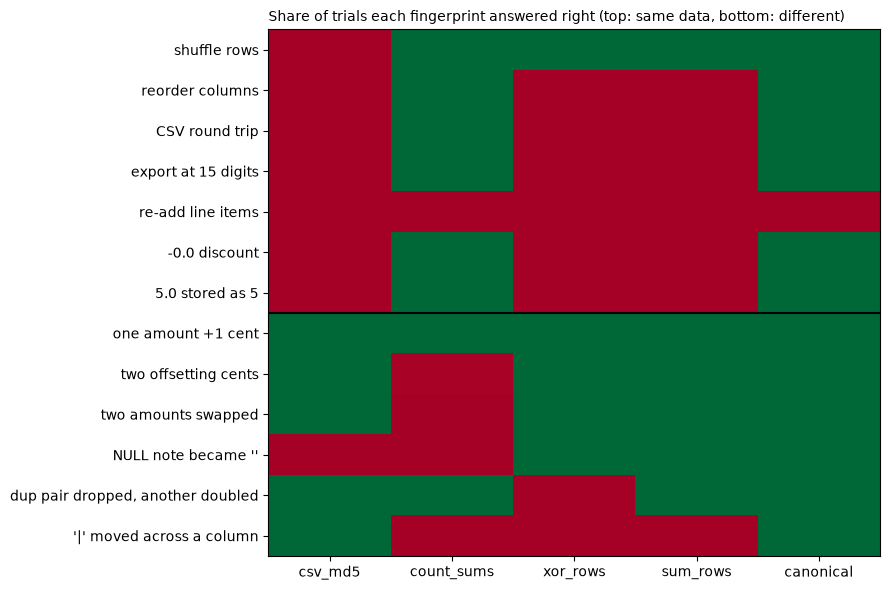

In [7]:
names = list(r["scores"]["benign"]) + list(r["scores"]["mutations"])
grid = [[(v["match"][k] if g == "benign" else 1 - v["match"][k]) for k in SCHEMES]
        for g in ("benign", "mutations") for v in r["scores"][g].values()]
fig, ax = plt.subplots(figsize=(9, 6))
ax.imshow(grid, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(SCHEMES)), list(SCHEMES))
ax.set_yticks(range(len(names)), names)
ax.axhline(len(r["scores"]["benign"]) - 0.5, color="black", lw=1.5)
ax.set_title("Share of trials each fingerprint answered right (top: same data, bottom: different)", loc="left", fontsize=10)
plt.tight_layout()
plt.savefig("notebook_chart.png", dpi=120)
plt.show()

## Summary

- A dump hash is a row-order test, not a data test: 7 false alarms of 7.
- Column sums are quiet and blind: 4 of 6 real changes pass, including two amounts swapped between rows.
- XOR cancels pairs, and a keyless table has pairs; a `|`-join cannot see a `|` in the data.
- Canonical, typed, summed row hashes got 12 of 13 right, and needed the schema declared to do it.
- The thirteenth is a half cent: round money once at load, not at compare time.

## 7. Try your own

In [8]:
# t, items = make_table()
# mine = (list(t[0]), [dict(r) for r in t[1]])
# mine[1][0]["note"] = "changed"
# for k, f in SCHEMES.items():
#     print(k, "match" if f(mine) == f(t) else "differ")

---
Part of [phoebe-the-builder](https://github.com/phoebefu6/phoebe-the-builder). The Streamlit version compares your
own two tables pasted as CSV: `pip install -r requirements.txt && streamlit run app.py`.